# Quickstart

> Simulate one week of Deep Space Network tracking of **OSIRIS-REx on approach to Bennu (June 2018)** and estimate its trajectory with a batch square-root information filter.
>
> ⏱ ~5 min &nbsp;·&nbsp; **Prereqs:** [Installation & tutorial data](README.md) &nbsp;·&nbsp; **Next:** [1. The scenario](01_scenario.ipynb)

This page runs the complete navigation workflow end to end: load the SPICE kernels, define the spacecraft, propagate a reference truth trajectory, simulate two-way range and range-rate from the three DSN complexes, and estimate the initial state from a perturbed guess. Explanations are kept to a minimum; each step is covered in detail in chapters [1](01_scenario.ipynb)–[6](06_first_od_solution.ipynb).

In [1]:
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import scarabaeus as scb

np.random.seed(2018)  # reproducible measurement noise
out = Path("outputs/00_quickstart")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
kg, km, m, sec, minute, day = scb.Units.get_units(
    ["kg", "km", "m", "sec", "min", "day"]
)
J2000 = scb.Frame("J2000")
sun = scb.CelestialBody.from_constants("SUN")

## 1. Scenario

One week sampled every 30 minutes. The initial state is taken from the flight team's reconstructed OSIRIS-REx ephemeris (SPICE ID `-64`). Two spacecraft with identical physical properties are defined: the **truth**, used to simulate measurements, and the **reference**, from which the filter starts.

In [2]:
epochs = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    dt=scb.ArrayWUnits(30, minute),
    sys="TDB",
)

x0 = scb.Spacecraft("OSIRIS-REx (flight)", -64).get_state(
    epochs[0], reference_frame="J2000", origin="SUN"
)
r0, v0 = x0.quantity[:3], x0.quantity[3:]

mass, area, cr = (
    scb.ArrayWUnits(1500.0, kg),
    scb.ArrayWUnits(11.0, m**2).convert_to(km**2),
    scb.ArrayWUnits(1.2, None),
)
truth_sc = scb.Spacecraft("OREx truth", -64000, mass, area, cr)
ref_sc = scb.Spacecraft("OREx reference", -64001, mass, area, cr)

## 2. Truth trajectory

Sun point-mass gravity, planetary third-body perturbations, and cannonball solar radiation pressure (SRP). The trajectory is written to an SPK file, which makes it available to every SPICE-based query that follows.

In [3]:
planets = ["MERCURY", "VENUS", "EARTH", "MARS", "JUPITER", "SATURN"]

truth_state = (
    scb.StateDefinition()
    .position(truth_sc, scb.ArrayWFrame(r0, J2000))
    .velocity(truth_sc, scb.ArrayWFrame(v0, J2000))
)
truth = scb.Propagator(
    primary_body=truth_sc,
    state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=truth_state),
    tspan=epochs,
    force_models=scb.ForceModelTranslation(
        truth_sc, third_bodies=planets, cannonball_SRP=True
    ),
    display_progress=False,
)
truth.propagate()

scb.Trajectory(state_array=truth.propagated_state_array).write_to_spk(
    str(out / "truth.bsp")
)
scb.SpiceManager.load_kernel(str(out / "truth.bsp"))

## 3. Simulated tracking data

Range (σ = 2 m) and range-rate (σ = 0.1 mm/s) from Goldstone (DSS-14), Canberra (DSS-43) and Madrid (DSS-63), every 30 minutes while the spacecraft is above a 10° elevation mask. These *ideal* models are instantaneous and geometric; station locations and Earth orientation come from the kernel pool. `MeasurementScheduler` checks visibility, simulates the noisy measurements, writes them in the Scarabaeus measurement file format (shared with converted real tracking data), and returns the `MeasurementSpec` the filter takes for each data type.

In [4]:
scheduler = scb.MeasurementScheduler(
    target=truth_sc,
    start=epochs,
    end=scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    cadence=scb.ArrayWUnits(30, minute),
    elevation_mask=10.0,
    noisy=True,
    output_dir=str(out),
)

tracking = []
for dss in ["DSS-14", "DSS-43", "DSS-63"]:
    station = scb.GroundStation(dss)
    for model_type, kind, sigma in [
        (scb.RangeIdeal, "range", scb.ArrayWUnits(2.0, m).convert_to(km)),
        (scb.RangeRateIdeal, "range-rate", scb.ArrayWUnits(1e-7, km / sec)),
    ]:
        name = f"{dss} {kind}"
        tracking.append(
            scheduler.schedule(station, model_type, sigma=sigma, name=name,
                               dataset_name=name, file_name=name.replace(" ", "_"))
        )

## 4. Orbit determination

The filter's reference trajectory starts 17 km and 1.7 cm/s from the truth, with a loose a-priori covariance. `fit()` iterates the batch filter, re-propagating the reference (and its state transition matrix) after each correction, until convergence.

In [5]:
%%capture filter_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
ref_state = (scb.StateDefinition()
             .position(ref_sc, scb.ArrayWFrame(r0 + scb.ArrayWUnits([10.0] * 3, km), J2000))
             .velocity(ref_sc, scb.ArrayWFrame(v0 + scb.ArrayWUnits([1e-5] * 3, km / sec), J2000)))
reference = scb.Propagator(primary_body=ref_sc,
                           state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=ref_state),
                           tspan=epochs,
                           force_models=scb.ForceModelTranslation(ref_sc, third_bodies=planets, cannonball_SRP=True),
                           display_progress=False)

P0 = scb.CovarianceMatrix([scb.ArrayWUnits(100.0, km)] * 3 + [scb.ArrayWUnits(1e-4, km / sec)] * 3,
                          epochs[0], from_list=True)

srifb = scb.SRIFB(propagator=reference,
                  measurements=scb.MeasurementSpec.many(*tracking),
                  settings=scb.FilterSettings(initial_covariance=P0),
                  traj_name="reference.bsp", traj_dir=str(out))
solution, n_iter, converged = srifb.fit(traj_name="reference.bsp", traj_dir=str(out),
                                        convergence_threshold=1e-5, verbose=False)

In [6]:
print(f"Converged: {converged} after {n_iter} iterations\n")
solution.print_stats()
solution.save(out / "solution.json")

Converged: True after 2 iterations

ORBIT DETERMINATION SOLUTION STATISTICS

Solution Overview:
  Number of epochs:        270
  Number of states:        6
  Covariance analysis:     False

Chi-Squared Test:
  Chi-squared value:       600.0736
  Degrees of freedom:      626
  Normalized chi-squared:  0.9586
  Status:                  Filter appears well-tuned

Covariance Information:
  Initial position uncertainty (1σ):
    X: 7.540777e-01 km
    Y: 9.212231e-01 km
    Z: 1.017740e+00 km
    RSS: 1.566231e+00 km
  Final position uncertainty (1σ):
    X: 8.402855e-01 km
    Y: 9.462019e-01 km
    Z: 1.125326e+00 km
    RSS: 1.693439e+00 km
  Initial velocity uncertainty (1σ):
    VX: 3.017435e-07 km/s
    VY: 1.175928e-06 km/s
    VZ: 9.514246e-07 km/s
    RSS: 1.542422e-06 km/s
  Final velocity uncertainty (1σ):
    VX: 2.921283e-07 km/s
    VY: 1.175687e-06 km/s
    VZ: 9.518281e-07 km/s
    RSS: 1.540635e-06 km/s
[SolutionOD] All iterations saved → outputs/00_quickstart/solution.json

## 5. Results

Since the data are simulated, the estimate can be compared directly with the truth. `Plotting.plot_state_errors` draws the error of each state component against the filter's ±3σ:

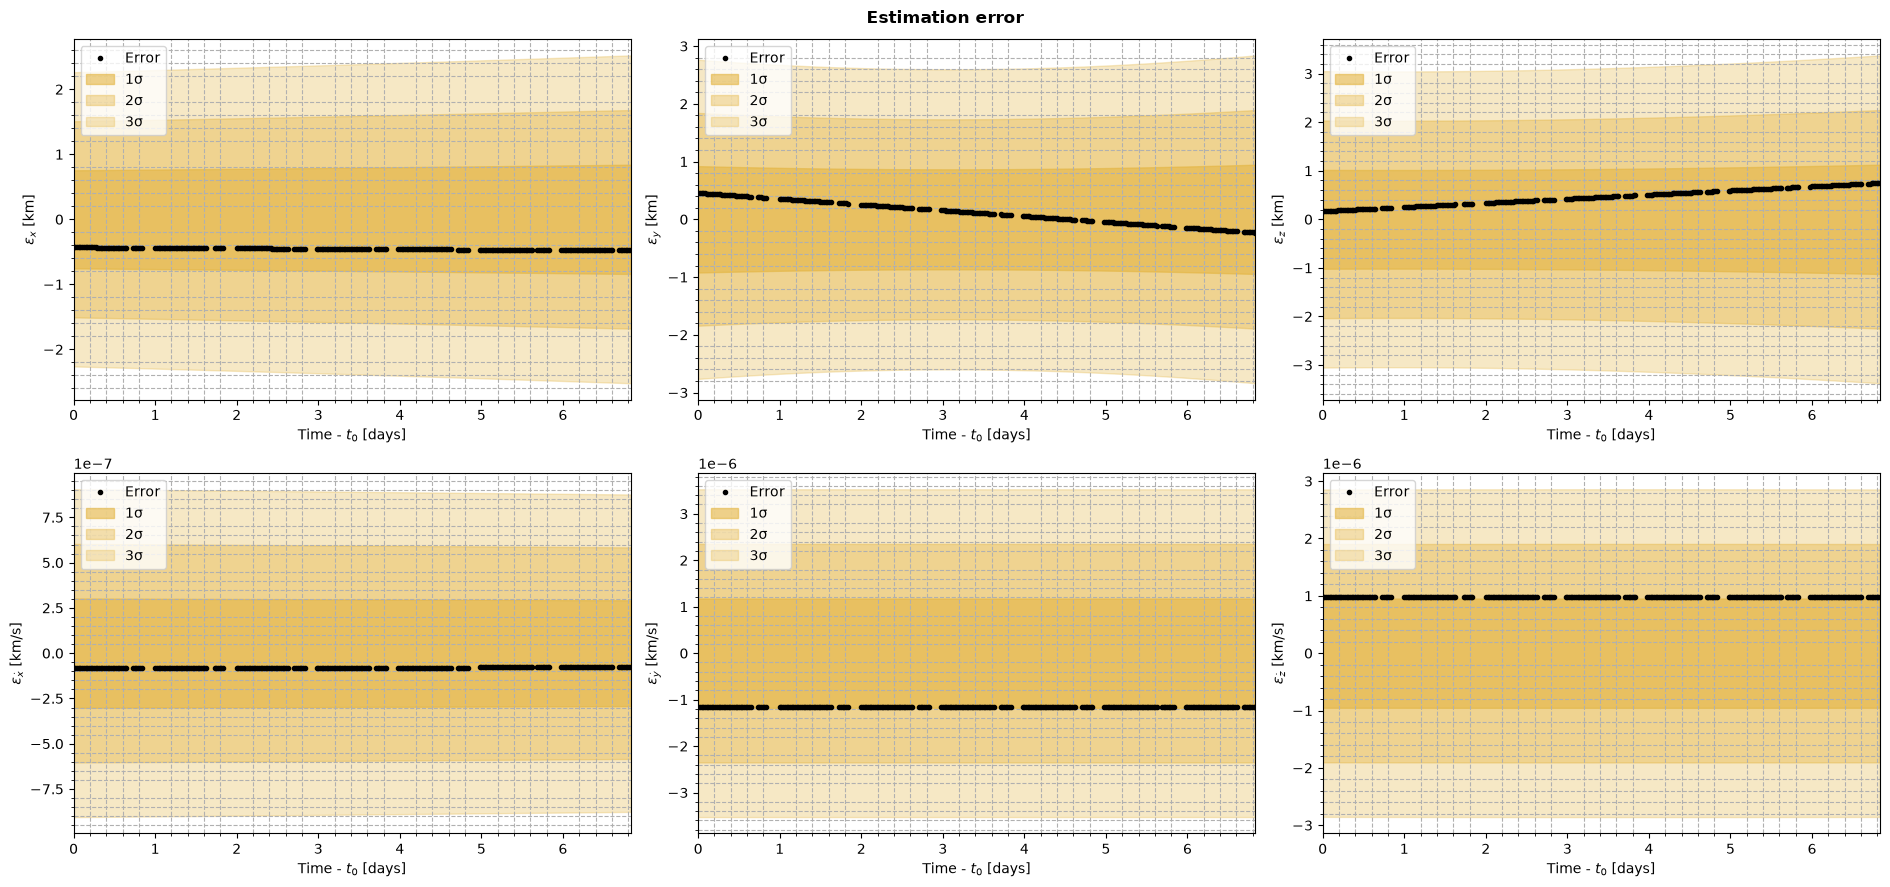

In [7]:
truth = scb.Trajectory(ref_frame=J2000, origin=sun, body=truth_sc)
t_est = scb.EpochArray(solution.timestamps, sys="TDB")  # the measurement epochs

scb.Plotting.plot_state_errors(solution, truth, t_est, n_sigma=3, title="Estimation error");

The estimate starts 17 km from the truth and is within 1 km of it after the fit, inside the filter's 1σ for every component over the whole week. The saved solution also holds the residuals of every iteration; the weighted post-fit residuals of the converged solution:

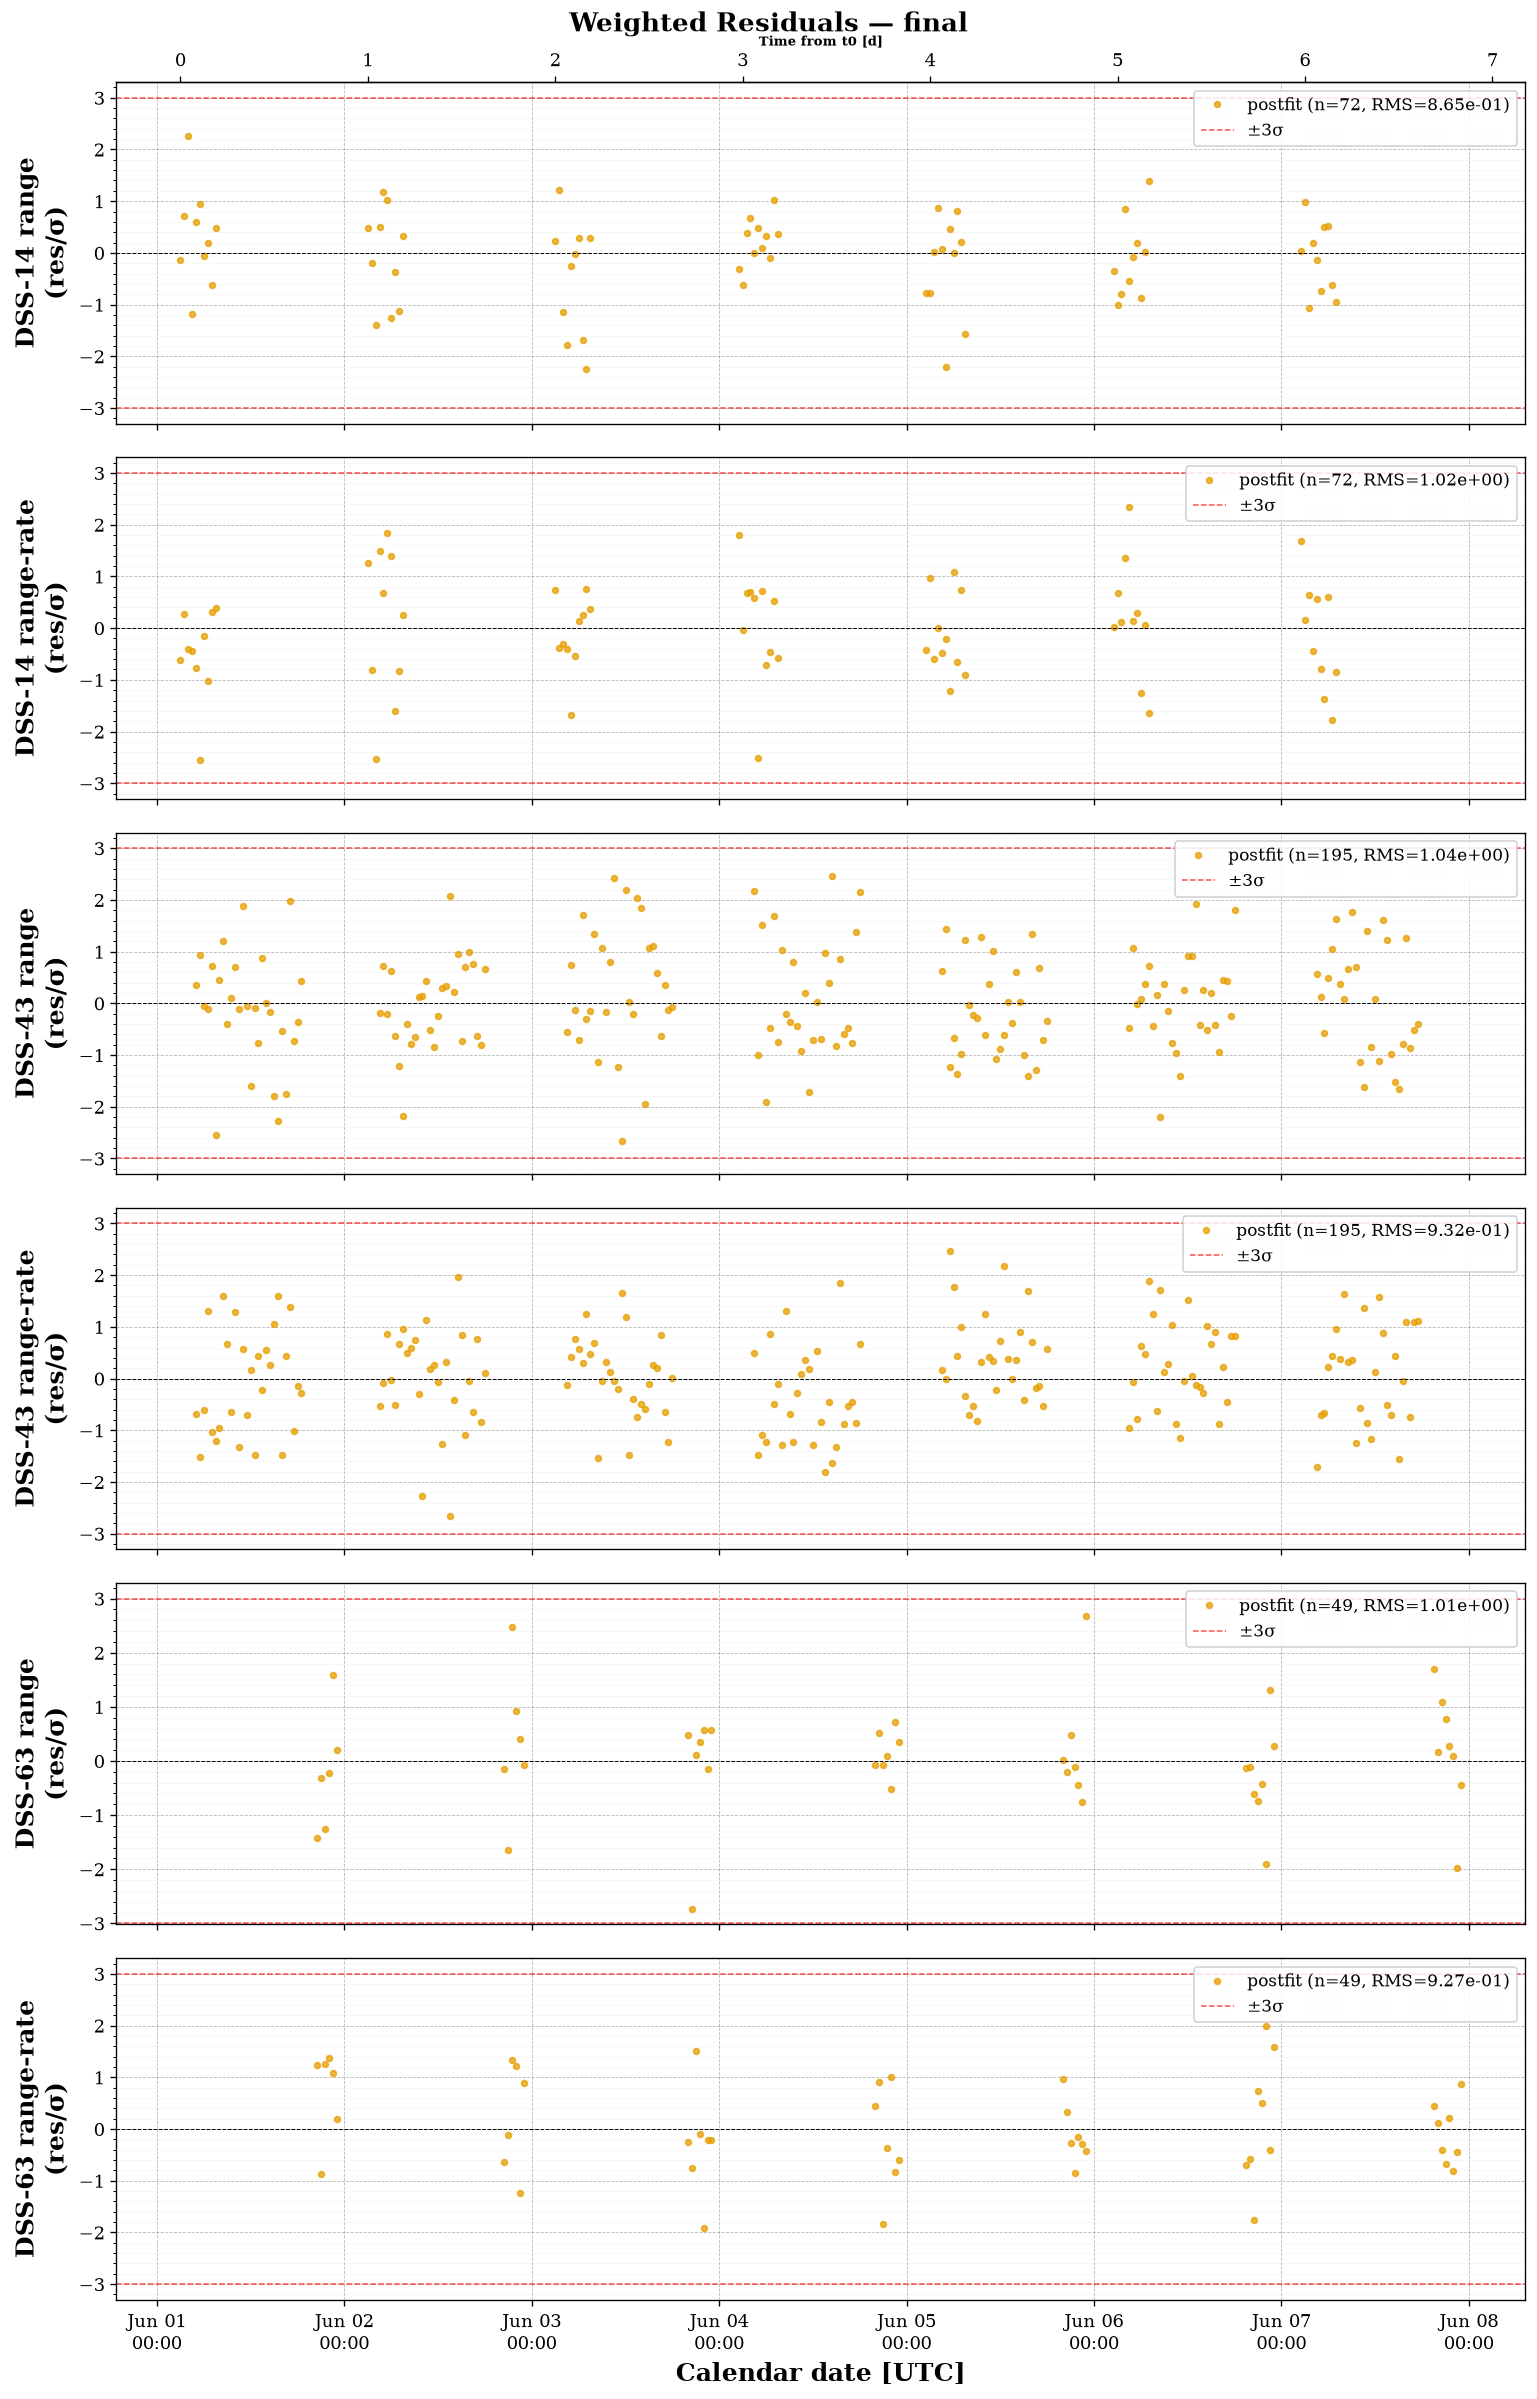

In [8]:
scb.Plotting.plot_residuals_json(out / "solution.json", iteration="final", kind="postfit", weighted=True, time_unit="day");

Each panel is one data type from one complex, and each cluster is a pass. The residuals are white, centered on zero, and within ±3σ, with an RMS near 1: the filter's models are consistent with the data. Chapter [6](06_first_od_solution.ipynb) goes through these checks in detail.

## Summary

| Step | Scarabaeus classes | Covered in |
|---|---|---|
| Kernels, time, bodies | `SpiceManager`, `EpochArray`, `CelestialBody`, `Spacecraft` | [1. The scenario](01_scenario.ipynb) |
| Truth propagation | `StateDefinition`, `StateArray`, `ForceModelTranslation`, `Propagator`, `Trajectory` | [2. Truth: dynamics & propagation](02_truth_dynamics.ipynb) |
| Tracking data | `GroundStation`, `RangeIdeal`, `RangeRateIdeal`, `MeasurementScheduler` | [3. Tracking data I](03_tracking_data.ipynb) |
| Filter dynamics model | reference `Propagator`, `CovarianceMatrix` | [4. The filter's dynamics model](04_filter_dynamics.ipynb) |
| Filter measurement model | `MeasurementSpec` | [5. The filter's measurement model](05_filter_measurements.ipynb) |
| Estimation and results | `FilterSettings`, `SRIFB`, `SolutionOD`, `Plotting` | [6. First OD solution](06_first_od_solution.ipynb) |

**Next steps:** start the series with [1. The scenario](01_scenario.ipynb), or jump to a specific topic in *Fundamentals* and the *Model catalogs*.